# **0. Preparation – Environment Setup**

### 0.1. Import Libraries

Import các thư viện cần thiết cho quá trình khảo sát, tiền xử lý và quản lý dữ liệu.

- `Path`: Quản lý đường dẫn và thao tác với thư mục, file.
- `xml.etree.ElementTree`: Đọc và trích xuất thông tin từ XML annotations.
- `pandas`, `numpy`: Xử lý và thống kê dữ liệu.
- `matplotlib`: Trực quan hóa ảnh và phân bố dữ liệu.
- `PIL`: Đọc, crop, resize và lưu ảnh.
- `Counter`: Thống kê tần suất xuất hiện của các ký tự.
- `scikit-learn`: Chia dữ liệu thành các tập train, validation và test.
- `tqdm`: Hiển thị tiến trình khi xử lý số lượng lớn file.
- `json`, `re`: Lưu character vocabulary và kiểm tra định dạng nhãn.

Các thư viện này được sử dụng xuyên suốt ba giai đoạn Data Exploration, Manifest Creation và Preprocessing.

In [28]:
from pathlib import Path
import json
import re
import xml.etree.ElementTree as ET

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from collections import Counter
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

### 0.2. Define Dataset Paths and Configuration

Khai báo đường dẫn đến các thư mục dữ liệu và thiết lập những tham số sử dụng trong quá trình xử lý.

Dataset được tổ chức thành hai phần chính:

- `localization/images`: Chứa ảnh container gốc.
- `localization/labels`: Chứa XML annotations, bao gồm nhãn ký tự và tọa độ bounding box.
- `recognition/images_with_labels`: Chứa ảnh thuộc bộ recognition, được giữ lại để khảo sát và đối chiếu.

Thư mục `outputs/task3` được sử dụng để lưu manifest, ảnh crop, character vocabulary và các báo cáo thống kê.

Các tham số chính gồm:

- `SEED = 42`: Cố định seed để đảm bảo khả năng tái lập kết quả.
- `TRAIN_RATIO`, `VAL_RATIO`, `TEST_RATIO`: Tỷ lệ chia dữ liệu tương ứng 70%, 15% và 15%.
- `TARGET_HEIGHT = 64`, `TARGET_WIDTH = 512`: Kích thước ảnh sau preprocessing.
- `LABEL_PATTERN`: Biểu thức kiểm tra định dạng mã container gồm 4 chữ cái in hoa và 7 chữ số.

Cuối cùng, kiểm tra sự tồn tại của các thư mục cần thiết trước khi thực hiện các bước tiếp theo.

In [29]:
DATA_DIR = Path("Data/acclr_dataset")

# Đường dẫn dữ liệu
localization_dir = DATA_DIR / "localization"
IMG_DIR = localization_dir / "images"
XML_DIR = localization_dir / "labels"
REC_DIR = DATA_DIR / "recognition/images_with_labels"

# Đường dẫn lưu kết quả
OUTPUT_DIR = Path("outputs/task3")
CROP_DIR = OUTPUT_DIR / "crops"
REPORT_DIR = OUTPUT_DIR / "reports"

for folder in [OUTPUT_DIR, CROP_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Cấu hình
SEED = 42
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

TARGET_HEIGHT, TARGET_WIDTH = 64, 512
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
LABEL_PATTERN = re.compile(r"^[A-Z]{4}[0-9]{7}$")

# Kiểm tra đường dẫn
print("Image directory:", IMG_DIR.resolve())
print("XML directory:", XML_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

assert IMG_DIR.exists(), f"Không tìm thấy thư mục: {IMG_DIR}"
assert XML_DIR.exists(), f"Không tìm thấy thư mục: {XML_DIR}"
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1) < 1e-9

Image directory: D:\Code trên lớp\DL_final\Deep-Learning-Project-2\Data\acclr_dataset\localization\images
XML directory: D:\Code trên lớp\DL_final\Deep-Learning-Project-2\Data\acclr_dataset\localization\labels
Output directory: D:\Code trên lớp\DL_final\Deep-Learning-Project-2\outputs\task3


# **01. Data Exploration**

Giai đoạn này nhằm khảo sát cấu trúc và đặc điểm của bộ dữ liệu ACCLR trước khi thực hiện tiền xử lý. Các nội dung được kiểm tra bao gồm số lượng hình ảnh, số lượng tệp XML annotations, thông tin hình ảnh và đặc điểm của các nhãn.

### 1.1. Khảo sát cấu trúc và số lượng tệp

Thống kê số lượng tệp trong từng thư mục của bộ dữ liệu.

Cụ thể:
- Đếm số lượng hình ảnh trong `localization/images`.
- Đếm số lượng tệp XML trong `localization/labels`.
- Đếm số lượng hình ảnh trong `recognition/images_with_labels` nếu thư mục tồn tại.

Kết quả được tổng hợp thành bảng để đánh giá quy mô dữ liệu và đối chiếu với các bước xử lý tiếp theo.

Lưu ý: Hình ảnh trong thư mục recognition được thống kê riêng, chưa được sử dụng thay thế cho hình ảnh localization.

In [30]:
image_files = sorted(p for p in IMG_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
xml_files = sorted(XML_DIR.rglob("*.xml"))
recognition_files = sorted(p for p in REC_DIR.rglob("*") if p.suffix.lower() in IMAGE_EXTS) if REC_DIR.exists() else []

file_stats = pd.DataFrame({
    "Data type": ["Localization images", "XML annotations", "Recognition images"],
    "Count": [len(image_files), len(xml_files), len(recognition_files)]
})

display(file_stats)
file_stats.to_csv(REPORT_DIR / "file_statistics.csv", index=False)

,Data type,Count
0,Localization images,4415
1,XML annotations,4859
2,Recognition images,15318


### 1.2. Phân tích đặc điểm hình ảnh

Kiểm tra các đặc điểm cơ bản của hình ảnh trong thư mục localization.

Các thông tin được thu thập gồm:

- `width`, `height`: Chiều rộng và chiều cao hình ảnh.
- `mode`: Chế độ màu của hình ảnh, ví dụ RGB, L hoặc RGBA.
- `format`: Định dạng tệp hình ảnh như JPEG hoặc PNG.

Sau khi thu thập, sử dụng các thống kê mô tả để xem xét phân bố kích thước và loại hình ảnh.

Mục đích là xác định mức độ đồng nhất của dữ liệu hình ảnh, từ đó lựa chọn phương pháp thay đổi kích thước và chuẩn hóa phù hợp.

In [31]:
image_info = []

for path in tqdm(image_files, desc="Inspecting images"):
    try:
        with Image.open(path) as img:
            image_info.append({
                "filename": path.name,
                "image_path": str(path),
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "format": img.format
            })
    except Exception as e:
        image_info.append({"filename": path.name, "image_path": str(path), "error": str(e)})

image_df = pd.DataFrame(image_info)
valid_image_info = image_df.dropna(subset=["width", "height"]).copy()

display(valid_image_info[["width", "height"]].describe())
display(valid_image_info["mode"].value_counts())
display(valid_image_info["format"].value_counts())

image_df.to_csv(REPORT_DIR / "image_statistics.csv", index=False)

Inspecting images:   0%|          | 0/4415 [00:00<?, ?it/s]

,width,height
count,4415.000000,4415.000000
mean,1763.076331,1037.509853
std,429.708409,154.016272
min,640.000000,640.000000
25%,1920.000000,1080.000000
50%,1920.000000,1080.000000
75%,1920.000000,1080.000000
max,2008.000000,1244.000000


mode
RGB    4415
Name: count, dtype: int64

format
JPEG    4415
Name: count, dtype: int64

#### 1.2.1. Trực quan hóa kích thước ảnh

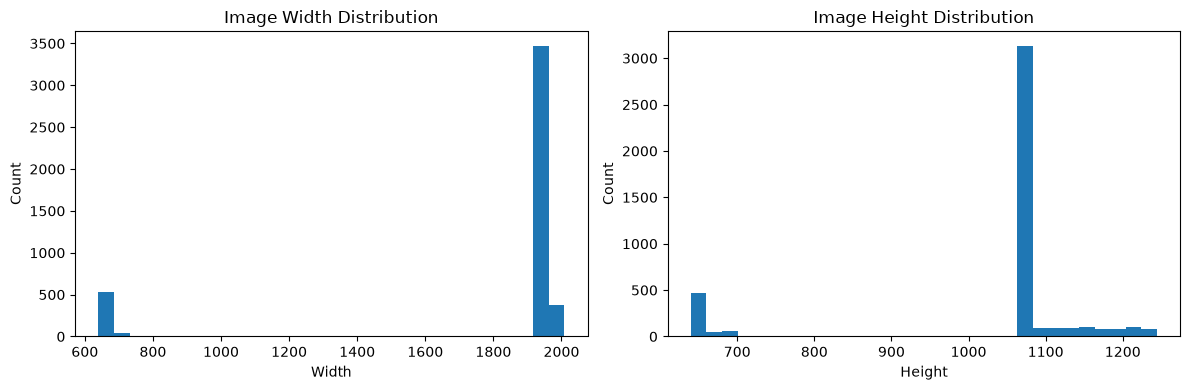

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(valid_image_info["width"], bins=30)
axes[0].set(title="Image Width Distribution", xlabel="Width", ylabel="Count")

axes[1].hist(valid_image_info["height"], bins=30)
axes[1].set(title="Image Height Distribution", xlabel="Height", ylabel="Count")

plt.tight_layout()
plt.show()

### 1.3. Trực quan hóa hình ảnh gốc

Hiển thị một số hình ảnh container được lấy từ tập dữ liệu để quan sát trực tiếp đặc điểm hình ảnh.

Thông qua việc trực quan hóa, có thể kiểm tra:

- Nội dung và chất lượng hình ảnh gốc.
- Sự khác nhau về góc chụp, ánh sáng và độ phân giải.
- Vị trí tương đối của mã container trên bề mặt container.
- Những yếu tố có thể ảnh hưởng đến quá trình nhận diện ký tự.

Đây là bước kiểm tra trực quan ban đầu trước khi sử dụng bounding box để trích xuất vùng chứa mã.

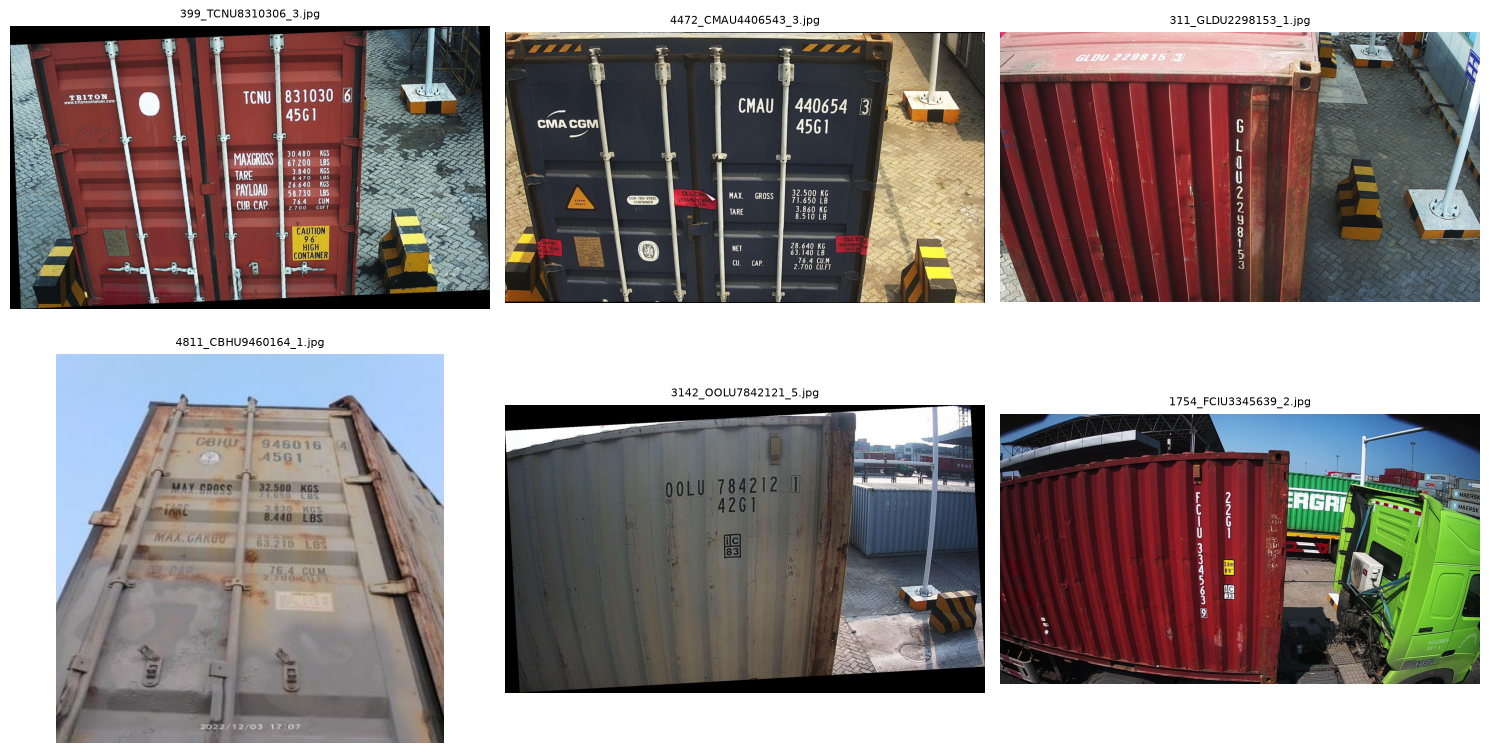

In [33]:
rng = np.random.default_rng(SEED)
sample_images = rng.choice(image_files, size=min(6, len(image_files)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, path in zip(axes.flat, sample_images):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(sample_images):]: ax.axis("off")

plt.tight_layout()
plt.show()

### 1.4. Khảo sát cấu trúc XML

Khảo sát cấu trúc các tệp XML để xác định thông tin cần thiết cho bài toán nhận diện chuỗi ký tự.

Dựa trên cấu trúc XML, các trường quan trọng được sử dụng gồm:

- `filename`: Tên hình ảnh gốc tương ứng với annotation.
- `object/name`: Chuỗi mã container cần nhận diện.
- `object/bndbox`: Vùng giới hạn chứa mã container.
- `xmin`, `ymin`, `xmax`, `ymax`: Tọa độ của bounding box.

Hàm `parse_xml()` được xây dựng để đọc thông tin từ XML và trích xuất toàn bộ object. Việc xử lý tất cả object giúp tránh bỏ sót annotation nếu một tệp XML chứa nhiều vùng được gán nhãn.

Một số trường hợp thiếu bounding box hoặc thiếu giá trị tọa độ được ghi nhận để kiểm tra ở giai đoạn tạo bảng dữ liệu tổng hợp.

In [34]:
def parse_xml(xml_path):
    """Trích xuất tên tệp, nhãn và bounding box từ một annotation XML."""
    root = ET.parse(xml_path).getroot()
    filename = root.findtext("filename", default="").strip()
    objects = []

    for obj in root.findall("object"):
        text = obj.findtext("name", default="").strip()
        box = obj.find("bndbox")

        if box is None:
            objects.append({
                "filename": filename,
                "text": text,
                "bbox_missing": True,
                "xmin": np.nan,
                "ymin": np.nan,
                "xmax": np.nan,
                "ymax": np.nan,
            })
            continue

        coordinates = {}
        for key in ("xmin", "ymin", "xmax", "ymax"):
            value = box.findtext(key)
            try:
                coordinates[key] = float(value)
            except (TypeError, ValueError):
                coordinates[key] = np.nan

        objects.append({
            "filename": filename,
            "text": text,
            "bbox_missing": False,
            **coordinates,
        })

    return filename, objects

#### 1.4.1. Kiểm tra XML mẫu

In [35]:
if xml_files:
    sample_root = ET.parse(xml_files[0]).getroot()
    print(ET.tostring(sample_root, encoding="unicode"))
    print("\nParsed objects:")
    print(parse_xml(xml_files[0])[1])

<annotation>
   <folder />
   <filename>0_TEMU6372145_1.jpg</filename>
   <path />
   <source>
      <database>final_dataset</database>
   </source>
   <size>
      <width>1920</width>
      <height>1080</height>
      <depth>3</depth>
   </size>
   <segmented>0</segmented>
   <object>
      <name>TEMU6372145</name>
      <pose>Unspecified</pose>
      <truncated>0</truncated>
      <difficult>0</difficult>
      <bndbox>
         <xmin>599</xmin>
         <xmax>1112</xmax>
         <ymin>345</ymin>
         <ymax>422</ymax>
      </bndbox>
   </object>
</annotation>

Parsed objects:
[{'filename': '0_TEMU6372145_1.jpg', 'text': 'TEMU6372145', 'bbox_missing': False, 'xmin': 599.0, 'ymin': 345.0, 'xmax': 1112.0, 'ymax': 422.0}]


### 1.5. Phân tích nhãn và ký tự

Sau khi đọc XML, tiến hành thống kê các nhãn được trích xuất từ trường `object/name`.

Các nội dung phân tích bao gồm:

- Tổng số object được trích xuất.
- Số lượng mã container khác nhau.
- Phân bố độ dài của các nhãn.
- Tần suất xuất hiện của từng ký tự.

Biểu đồ độ dài nhãn giúp xác định cấu trúc chuỗi ký tự của dữ liệu. Trong khi đó, thống kê tần suất ký tự cung cấp thông tin về tập ký tự cần sử dụng và mức độ xuất hiện của từng ký tự.

Những thống kê này là cơ sở để thiết kế bước mã hóa ký tự và xác định số lượng lớp đầu ra của mô hình.

In [36]:
exploration_objects = []
xml_parse_errors = []

for xml_path in tqdm(xml_files, desc="Exploring XML"):
    try:
        _, objects = parse_xml(xml_path)
        exploration_objects.extend(objects)
    except Exception as e:
        xml_parse_errors.append({"xml_path": str(xml_path), "error": str(e)})

explore_df = pd.DataFrame(exploration_objects)
explore_df["label_length"] = explore_df["text"].fillna("").str.len()

print("Parsed XML files:", len(xml_files) - len(xml_parse_errors))
print("XML parsing errors:", len(xml_parse_errors))
print("Total objects:", len(explore_df))
print("Unique non-empty labels:", explore_df.loc[explore_df["text"].ne(""), "text"].nunique())

display(explore_df["label_length"].describe())
display(explore_df["text"].value_counts().head(20))

Exploring XML:   0%|          | 0/4859 [00:00<?, ?it/s]

Parsed XML files: 4859
XML parsing errors: 0
Total objects: 4859
Unique non-empty labels: 1351


count    4859.0
mean       11.0
std         0.0
min        11.0
25%        11.0
50%        11.0
75%        11.0
max        11.0
Name: label_length, dtype: float64

text
SEGU2473151    16
SEGU1845378    11
PONU0468770    11
ZCSU5845422    11
UACU8204203    11
TCKU4732187    10
HMCU3020504    10
UACU8365635    10
CSLU2271920     9
HMCU9189702     9
EISU9253334     9
EITU0295585     9
TGHU9951883     9
HMCU3008474     9
ZIMU1293896     9
SBAU2894437     9
EITU1174485     9
PONU0280273     9
HMCU9196722     9
WFHU5188287     9
Name: count, dtype: int64

#### 1.5.1. Phân bố độ dài nhãn

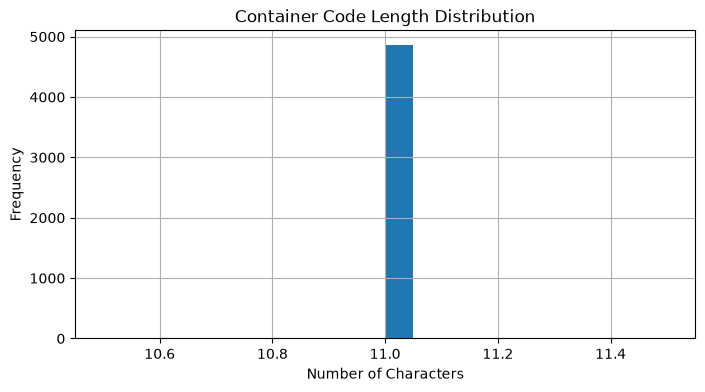

In [37]:
plt.figure(figsize=(8, 4))
explore_df["label_length"].hist(bins=20)
plt.title("Container Code Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

#### 1.5.2. Tần suất ký tự

,character,count
3,U,5054
22,0,3842
7,2,3736
5,3,3625
8,1,3477
10,5,3437
9,4,3372
18,9,3326
6,7,3183
15,8,3163


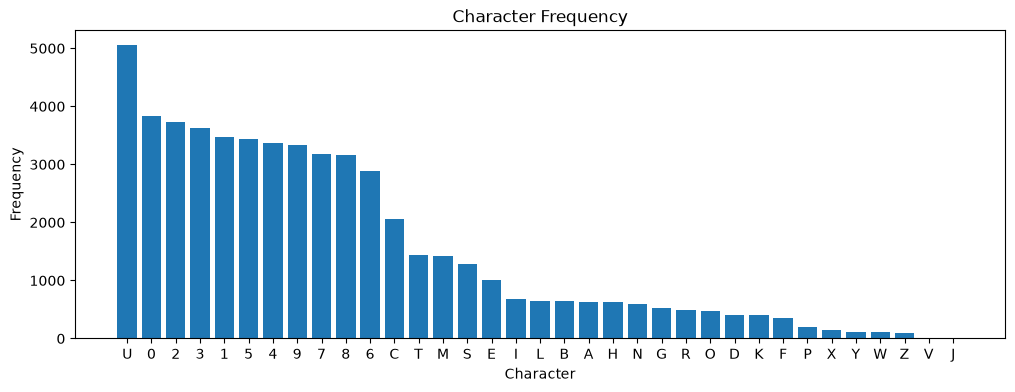

In [38]:
char_counts = Counter("".join(explore_df["text"].dropna().astype(str)))

char_df = pd.DataFrame(char_counts.items(), columns=["character", "count"]).sort_values("count", ascending=False)

display(char_df)

plt.figure(figsize=(12, 4))
plt.bar(char_df["character"], char_df["count"])
plt.title("Character Frequency")
plt.xlabel("Character")
plt.ylabel("Frequency")
plt.show()

### 1.6. Kiểm tra sơ bộ bounding box

Kiểm tra trực quan bounding box bằng cách hiển thị tọa độ annotation trên hình ảnh container gốc.

Mỗi bounding box được biểu diễn bằng hình chữ nhật, đồng thời hiển thị nhãn tương ứng để đối chiếu với vùng hình ảnh được khoanh.

Mục đích:

- Xác nhận bounding box có nằm đúng vị trí mã container hay không.
- Kiểm tra nhãn XML có tương ứng với nội dung trong hình ảnh hay không.
- Phát hiện sơ bộ các trường hợp bounding box bị lệch hoặc không bao phủ đầy đủ ký tự.

Kết quả của bước này giúp đánh giá ban đầu chất lượng annotation trước khi tiến hành kiểm tra chi tiết hơn.

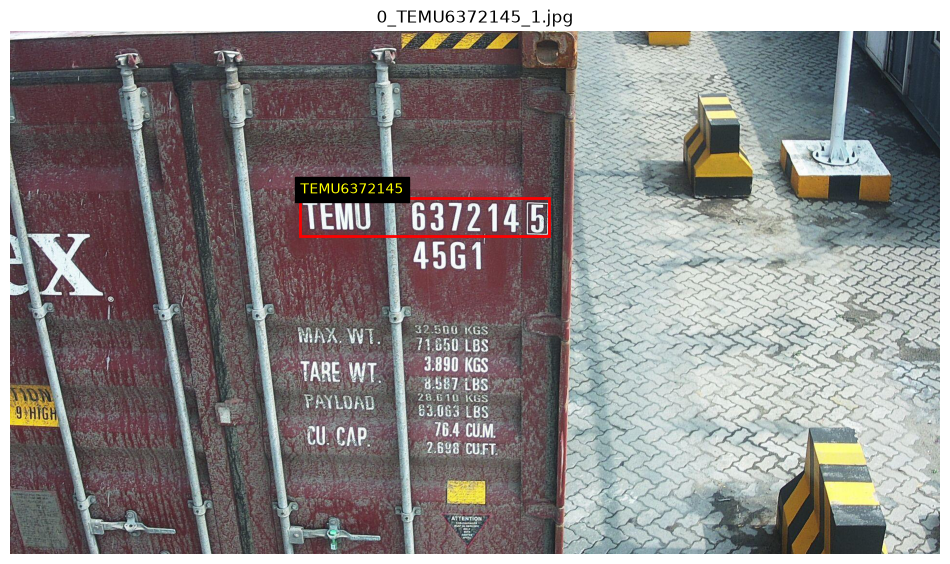

In [39]:
filename, objects = parse_xml(xml_files[0])
image_path = next(
    (path for path in image_files if path.name == filename),
    None,
)

if not objects:
    print("Không tìm thấy object hợp lệ trong file XML.")
elif image_path is None:
    print(f"Không tìm thấy ảnh: {filename}")
else:
    with Image.open(image_path) as img:
        fig, ax = plt.subplots(figsize=(12, 7))
        ax.imshow(img.convert("RGB"))

        for obj in objects:
            coordinate_keys = ("xmin", "ymin", "xmax", "ymax")
            if obj["bbox_missing"] or not all(
                np.isfinite(obj[key]) for key in coordinate_keys
            ):
                continue

            x1, y1 = int(obj["xmin"]), int(obj["ymin"])
            x2, y2 = int(obj["xmax"]), int(obj["ymax"])
            rect = patches.Rectangle(
                (x1 - 1, y1 - 1), x2 - x1 + 1, y2 - y1 + 1,
                linewidth=2, edgecolor="red", facecolor="none",
            )
            ax.add_patch(rect)
            ax.text(
                x1, max(0, y1 - 10), obj["text"],
                color="yellow", fontsize=10, backgroundcolor="black",
            )

        ax.set_title(filename)
        ax.axis("off")
        plt.show()

#### Trực quan hóa một mẫu annotation

Hình bên dưới minh họa cách sử dụng hàm `parse_xml()` thống nhất để kiểm tra nhãn và bounding box trên ảnh gốc.

# **02. Manifest Creation**

Sau khi khảo sát dữ liệu, tiến hành tổng hợp thông tin từ hình ảnh và XML annotations thành một bảng dữ liệu thống nhất (manifest).

Manifest đóng vai trò liên kết hình ảnh gốc với nhãn ký tự và tọa độ bounding box, giúp các bước tiền xử lý có thể truy xuất dữ liệu một cách nhất quán.

### 2.1. Ánh xạ hình ảnh

Xây dựng bảng ánh xạ giữa tên tệp hình ảnh và đường dẫn thực tế của hình ảnh trong thư mục localization.

Việc ánh xạ được thực hiện dựa trên tên tệp `filename` trong XML.

Đồng thời, kiểm tra các trường hợp có nhiều hình ảnh trùng tên để tránh ghép nhầm annotation với hình ảnh. Những tên tệp bị trùng sẽ được ghi nhận để kiểm tra riêng thay vì tự động chọn một đường dẫn bất kỳ.

In [40]:
image_groups = {}

for path in image_files:
    image_groups.setdefault(path.name, []).append(path)

duplicate_image_names = {name: paths for name, paths in image_groups.items() if len(paths) > 1}

print("Unique image filenames:", len(image_groups))
print("Duplicate image filenames:", len(duplicate_image_names))

image_lookup = {name: paths[0] for name, paths in image_groups.items() if len(paths) == 1}

Unique image filenames: 4415
Duplicate image filenames: 0


### 2.2. Đọc XML và trích xuất annotation

Đọc toàn bộ XML annotations và trích xuất các thông tin cần thiết để tạo manifest.

Với mỗi object trong XML, chương trình thu thập:

- Tên tệp hình ảnh.
- Đường dẫn hình ảnh tương ứng.
- Đường dẫn XML nguồn.
- Nhãn văn bản của mã container.
- Tọa độ bounding box.

Ngoài việc trích xuất dữ liệu, chương trình còn ghi nhận trạng thái xử lý của từng XML, bao gồm:

- XML đọc thành công hoặc gặp lỗi.
- Số lượng object được tìm thấy.
- Số object không tìm thấy hình ảnh tương ứng.
- Số nhãn rỗng.
- Số object thiếu bounding box.

Việc lưu riêng trạng thái xử lý giúp xác định tỷ lệ XML được đọc thành công và truy xuất các trường hợp lỗi khi cần thiết.

In [41]:
manifest_rows = []
xml_status = []

for xml_path in tqdm(xml_files, desc="Building manifest"):
    status = {
        "xml_path": str(xml_path),
        "xml_filename": xml_path.name,
        "parse_success": False,
        "object_count": 0,
        "missing_image_objects": 0,
        "empty_label_objects": 0,
        "missing_bbox_objects": 0,
        "error": ""
    }

    try:
        filename, objects = parse_xml(xml_path)
        status["parse_success"] = True
        status["object_count"] = len(objects)

        image_path = image_lookup.get(filename) if filename else None

        for obj in objects:
            text_value = str(obj.get("text", "")).strip()
            missing_bbox = obj.get("bbox_missing", False)
            bbox_values = [obj.get(k, np.nan) for k in ["xmin", "ymin", "xmax", "ymax"]]

            status["missing_image_objects"] += int(image_path is None)
            status["empty_label_objects"] += int(not text_value)
            status["missing_bbox_objects"] += int(missing_bbox or any(pd.isna(v) for v in bbox_values))

            manifest_rows.append({
                "filename": filename,
                "image_path": str(image_path) if image_path else None,
                "xml_path": str(xml_path),
                "text": text_value,
                "xmin": obj.get("xmin", np.nan),
                "ymin": obj.get("ymin", np.nan),
                "xmax": obj.get("xmax", np.nan),
                "ymax": obj.get("ymax", np.nan),
                "bbox_missing": missing_bbox
            })

        if not objects:
            status["error"] = "No objects found"

    except Exception as e:
        status["error"] = str(e)

    xml_status.append(status)

manifest_all = pd.DataFrame(manifest_rows)
xml_status_df = pd.DataFrame(xml_status)

print("XML files:", len(xml_files))
print("Successfully parsed:", int(xml_status_df["parse_success"].sum()))
print("Failed XML:", int((~xml_status_df["parse_success"]).sum()))
print("Extracted objects:", len(manifest_all))

xml_status_df.to_csv(REPORT_DIR / "xml_processing_status.csv", index=False)

Building manifest:   0%|          | 0/4859 [00:00<?, ?it/s]

XML files: 4859
Successfully parsed: 4859
Failed XML: 0
Extracted objects: 4859


### 2.3. Kiểm tra tính hợp lệ của manifest

Sau khi tổng hợp annotation, tiến hành kiểm tra tính đầy đủ và hợp lệ của từng bản ghi.

Các điều kiện được kiểm tra gồm:

1. Hình ảnh tương ứng có tồn tại trong thư mục hay không.
2. Nhãn có bị thiếu hoặc rỗng hay không.
3. Các tọa độ bounding box có đầy đủ giá trị số hay không.
4. Tọa độ có thỏa mãn điều kiện `xmin < xmax` và `ymin < ymax` hay không.
5. Bounding box có nằm trong phạm vi kích thước hình ảnh hay không.

Một bounding box chỉ được xem là hợp lệ khi đáp ứng đầy đủ các điều kiện về tọa độ và phạm vi hình ảnh.

Kết quả kiểm tra được tổng hợp thành bảng thống kê, giúp xác định số lượng bản ghi hợp lệ và các loại lỗi xuất hiện trong dữ liệu.

In [42]:
# Kiểm tra cấu trúc XML mẫu
xml_path = xml_files[0]
root = ET.parse(xml_path).getroot()

print("XML:", xml_path.name)
print("Filename:", root.findtext("filename", default=""))
print("Số object:", len(root.findall("object")))

for obj in root.findall("object")[:3]:
    bbox = obj.find("bndbox")
    print({
        "text": obj.findtext("name", default=""),
        "xmin": bbox.findtext("xmin") if bbox is not None else None,
        "ymin": bbox.findtext("ymin") if bbox is not None else None,
        "xmax": bbox.findtext("xmax") if bbox is not None else None,
        "ymax": bbox.findtext("ymax") if bbox is not None else None,
    })

XML: 0_TEMU6372145_1.xml
Filename: 0_TEMU6372145_1.jpg
Số object: 1
{'text': 'TEMU6372145', 'xmin': '599', 'ymin': '345', 'xmax': '1112', 'ymax': '422'}


Tạo bảng tổng kết các lỗi:

In [43]:
# 7. Tổng hợp chất lượng dữ liệu

# Thống kê số XML đã đọc thành công
# Mỗi XML thành công phải có ít nhất một bản ghi trong manifest
parsed_xml_files = manifest["xml_path"].nunique() if "xml_path" in manifest.columns else None

quality_summary = pd.DataFrame({
    "Check": [
        "Total XML files",
        "Successfully parsed XML",
        "Failed XML",
        "Total extracted objects",
        "Missing image",
        "Empty label",
        "Missing or invalid bbox",
        "Valid bbox",
        "Labels matching 4 letters + 7 digits"
    ],
    "Count": [
        len(xml_files),
        parsed_xml_files if parsed_xml_files is not None else "N/A",
        len(xml_files) - parsed_xml_files if parsed_xml_files is not None else "N/A",
        len(manifest),
        int((~manifest["image_exists"]).sum()),
        int(manifest["label_empty"].sum()),
        int((~manifest["bbox_valid"]).sum()),
        int(manifest["bbox_valid"].sum()),
        int(manifest["label_format_valid"].sum())
    ]
})

display(quality_summary)

,Check,Count
0,Total XML files,4859
1,Successfully parsed XML,4859
2,Failed XML,0
3,Total extracted objects,4859
4,Missing image,444
5,Empty label,0
6,Missing or invalid bbox,452
7,Valid bbox,4407
8,Labels matching 4 letters + 7 digits,4791


#### 2.4. Tỷ lệ XML được xử lý thành công

In [44]:
xml_success_rate = 100 * xml_status_df["parse_success"].mean() if len(xml_status_df) else 0
print(f"XML parsing success rate: {xml_success_rate:.2f}%")

XML parsing success rate: 100.00%


### 2.4. Phát hiện bounding box bất thường

Ngoài việc kiểm tra tọa độ có nằm trong hình ảnh hay không, cần đánh giá thêm kích thước và tỷ lệ của bounding box.

Các đặc trưng được tính toán gồm:

- `bbox_width`: Chiều rộng bounding box.
- `bbox_height`: Chiều cao bounding box.
- `bbox_area`: Diện tích bounding box.
- `bbox_ratio`: Tỷ lệ giữa chiều rộng và chiều cao.
- `bbox_area_ratio`: Tỷ lệ diện tích bounding box so với diện tích hình ảnh gốc.

Dựa trên các đặc trưng này, chương trình đánh dấu những bounding box có kích thước quá nhỏ, diện tích quá lớn hoặc tỷ lệ rộng/cao bất thường.

Các ngưỡng được sử dụng chỉ nhằm phát hiện những trường hợp cần kiểm tra thêm, không mặc định kết luận chúng là annotation sai.

Biểu đồ phân bố chiều rộng, chiều cao và tỷ lệ rộng/cao giúp quan sát sự đa dạng về hình dạng và kích thước của các vùng mã container.

In [45]:
bbox_df = manifest.copy()

bbox_df["bbox_width"] = bbox_df["xmax"] - bbox_df["xmin"] + 1
bbox_df["bbox_height"] = bbox_df["ymax"] - bbox_df["ymin"] + 1
bbox_df["bbox_area"] = bbox_df["bbox_width"] * bbox_df["bbox_height"]
bbox_df["bbox_ratio"] = bbox_df["bbox_width"] / bbox_df["bbox_height"].replace(0, np.nan)

def get_image_area(row):
    if not row["image_exists"]:
        return np.nan
    try:
        with Image.open(row["image_path"]) as img:
            return img.width * img.height
    except Exception:
        return np.nan

bbox_df["image_area"] = bbox_df.apply(get_image_area, axis=1)
bbox_df["bbox_area_ratio"] = bbox_df["bbox_area"] / bbox_df["image_area"]

#### Gán nhãn các trường hợp bất thường

Các ngưỡng dưới đây là ngưỡng phát hiện cần kiểm tra, có thể điều chỉnh tùy theo dữ liệu thực tế.

In [46]:
MIN_BBOX_WIDTH = 20
MIN_BBOX_HEIGHT = 10
MAX_BBOX_AREA_RATIO = 0.80
MAX_BBOX_ASPECT_RATIO = 20

bbox_df["bbox_too_small"] = (
    (bbox_df["bbox_width"] < MIN_BBOX_WIDTH) |
    (bbox_df["bbox_height"] < MIN_BBOX_HEIGHT)
)

bbox_df["bbox_too_large"] = bbox_df["bbox_area_ratio"] > MAX_BBOX_AREA_RATIO

bbox_df["bbox_extreme_ratio"] = (
    (bbox_df["bbox_ratio"] > MAX_BBOX_ASPECT_RATIO) |
    (bbox_df["bbox_ratio"] < 1 / MAX_BBOX_ASPECT_RATIO)
)

bbox_df["bbox_suspicious"] = (
    bbox_df["bbox_too_small"] |
    bbox_df["bbox_too_large"] |
    bbox_df["bbox_extreme_ratio"]
)

display(bbox_df[[
    "bbox_width", "bbox_height", "bbox_ratio", "bbox_area_ratio"
]].describe())

print("Suspicious bbox:", int(bbox_df["bbox_suspicious"].sum()))

,bbox_width,bbox_height,bbox_ratio,bbox_area_ratio
count,4859.000000,4859.000000,4859.000000,4415.000000
mean,339.017493,271.678535,3.957670,0.024143
std,218.648965,278.174421,2.883089,0.010764
min,30.000000,21.000000,0.055556,0.003995
25%,90.000000,75.000000,0.134073,0.017703
50%,415.000000,93.000000,4.970297,0.021505
75%,511.000000,622.000000,6.343284,0.027361
max,1005.000000,977.000000,11.428571,0.125073


Suspicious bbox: 0


#### Biểu đồ phân bố bounding box

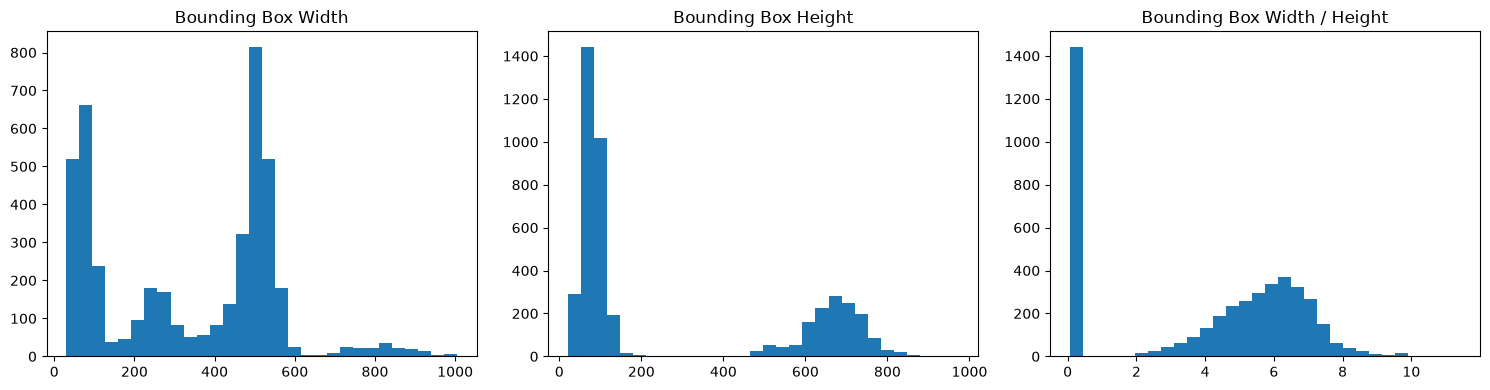

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(bbox_df.loc[bbox_df["bbox_valid"], "bbox_width"].dropna(), bins=30)
axes[0].set_title("Bounding Box Width")

axes[1].hist(bbox_df.loc[bbox_df["bbox_valid"], "bbox_height"].dropna(), bins=30)
axes[1].set_title("Bounding Box Height")

axes[2].hist(bbox_df.loc[bbox_df["bbox_valid"], "bbox_ratio"].dropna(), bins=30)
axes[2].set_title("Bounding Box Width / Height")

plt.tight_layout()
plt.show()

### 2.5. Kiểm tra định dạng mã container

Kiểm tra định dạng của các nhãn được trích xuất từ XML.

Theo cấu trúc mã container đang được sử dụng trong bài toán, nhãn được kỳ vọng có dạng:

- 4 chữ cái in hoa.
- Theo sau là 7 chữ số.

Ví dụ: `TEMU6372145`.

Sử dụng biểu thức chính quy (regular expression) để xác định các nhãn đáp ứng định dạng này và tách riêng những nhãn không hợp lệ để kiểm tra.

Việc kiểm tra giúp phát hiện các trường hợp thiếu ký tự, thừa ký tự hoặc sai cấu trúc nhãn trước khi đưa vào mô hình.

Các nhãn không hợp lệ không được tự động chỉnh sửa nhằm tránh thay đổi thông tin annotation gốc.

In [48]:
label_format_counts = manifest["label_format_valid"].value_counts(dropna=False)
display(label_format_counts)

invalid_labels = manifest.loc[~manifest["label_format_valid"], ["filename", "text", "xml_path"]]
display(invalid_labels.head(20))

invalid_labels.to_csv(REPORT_DIR / "invalid_labels.csv", index=False)

label_format_valid
True     4791
False      68
Name: count, dtype: int64

,filename,text,xml_path
93,1084_TCLU541OO32_1.jpg,TCLU541OO32,Data\acclr_dataset\localization\labels\1084_TC...
94,1085_TCLU541OO32_2.jpg,TCLU541OO32,Data\acclr_dataset\localization\labels\1085_TC...
95,1086_TCLU541OO32_3.jpg,TCLU541OO32,Data\acclr_dataset\localization\labels\1086_TC...
116,1104_BM0U5787950_1.jpg,BM0U5787950,Data\acclr_dataset\localization\labels\1104_BM...
117,1105_BM0U5787950_2.jpg,BM0U5787950,Data\acclr_dataset\localization\labels\1105_BM...
118,1106_BM0U5787950_3.jpg,BM0U5787950,Data\acclr_dataset\localization\labels\1106_BM...
157,1141_0NTU1604421_1.jpg,0NTU1604421,Data\acclr_dataset\localization\labels\1141_0N...
158,1142_0NTU1604421_2.jpg,0NTU1604421,Data\acclr_dataset\localization\labels\1142_0N...
159,1143_0NTU1604421_3.jpg,0NTU1604421,Data\acclr_dataset\localization\labels\1143_0N...
254,1229_00LU6509440_1.jpg,00LU6509440,Data\acclr_dataset\localization\labels\1229_00...


## 05. Kết luận

Ba giai đoạn chính của Task 3 đã được triển khai: khảo sát dữ liệu, tạo manifest và tiền xử lý.

- Bộ dữ liệu được phân tích theo cấu trúc hình ảnh, XML, bounding box và nhãn ký tự.
- Manifest liên kết ảnh gốc, tọa độ vùng mã và nhãn container.
- Dữ liệu hợp lệ được loại trùng lặp, chia theo container nhằm hạn chế rò rỉ dữ liệu.
- Bộ ký tự chỉ được xây dựng từ tập huấn luyện.
- Ảnh được crop, resize với padding và chuẩn hóa cho mô hình Image-to-Sequence với CTC.

Các bounding box bất thường vẫn cần được kiểm tra trực quan trước khi huấn luyện. Giai đoạn tiếp theo có thể xây dựng DataLoader, kiến trúc CNN–BiLSTM–CTC, huấn luyện mô hình và đánh giá bằng CER và Exact Match Accuracy.

In [49]:
manifest["container_id"] = manifest["text"]

manifest["record_valid"] = (
    manifest["image_exists"] &
    ~manifest["label_empty"] &
    manifest["bbox_valid"] &
    manifest["label_format_valid"]
)

manifest.to_csv(OUTPUT_DIR / "manifest_all_records.csv", index=False, encoding="utf-8-sig")

valid_manifest = manifest.loc[manifest["record_valid"]].copy()
valid_manifest = valid_manifest.drop_duplicates(
    subset=["image_path", "xmin", "ymin", "xmax", "ymax", "text"]
).reset_index(drop=True)

print("All extracted records:", len(manifest))
print("Valid records before deduplication:", int(manifest["record_valid"].sum()))
print("Valid unique records:", len(valid_manifest))
print("Unique container codes:", valid_manifest["text"].nunique())

valid_manifest.to_csv(OUTPUT_DIR / "manifest.csv", index=False, encoding="utf-8-sig")

All extracted records: 4859
Valid records before deduplication: 4339
Valid unique records: 4339
Unique container codes: 1206


### 2.7. Kiểm tra trực quan bounding box bất thường

Thực hiện kiểm tra trực quan những bounding box được đánh dấu bất thường nhưng vẫn vượt qua các điều kiện kiểm tra tọa độ cơ bản.

Các vùng mã được hiển thị trên hình ảnh gốc cùng với nhãn và tỷ lệ rộng/cao tương ứng.

Mục đích là xác định liệu những trường hợp bất thường có thực sự là lỗi annotation hay chỉ phản ánh sự khác biệt về góc chụp, kích thước và vị trí mã container.

Đây là bước kiểm tra cần thiết vì các tiêu chí thống kê không thể thay thế hoàn toàn việc đánh giá chất lượng bounding box bằng hình ảnh thực tế.

In [50]:
def show_bbox_row(row):
    with Image.open(row["image_path"]) as img:
        fig, ax = plt.subplots(figsize=(12, 6))
        ax.imshow(img.convert("RGB"))

        x1, y1 = row["xmin"] - 1, row["ymin"] - 1
        w, h = row["bbox_width"], row["bbox_height"]

        rect = plt.Rectangle((x1, y1), w, h, linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)
        ax.set_title(f"{row['filename']} | {row['text']} | ratio={row['bbox_ratio']:.2f}")
        ax.axis("off")
        plt.show()

suspicious_samples = bbox_df.loc[
    bbox_df["bbox_suspicious"] & bbox_df["bbox_valid"]
].head(12)

for _, row in suspicious_samples.iterrows():
    show_bbox_row(row)

# **03. Preprocessing**

Giai đoạn này chuyển dữ liệu ảnh và nhãn sang định dạng phù hợp cho bài toán Image-to-Sequence Prediction.

Trước khi crop và encoding, dữ liệu được chia thành các tập train, validation và test theo mã container nhằm hạn chế data leakage.

### 3.1. Group-based Data Splitting

Không chia ngẫu nhiên từng ảnh vì một mã container có thể xuất hiện trong nhiều ảnh khác nhau. Nếu những ảnh này đồng thời xuất hiện trong train và test, mô hình có thể ghi nhớ các mã đã gặp thay vì học khả năng nhận diện trên những mã mới.

Vì vậy, sử dụng `container_id` để chia nhóm dữ liệu:

- Training: 70%.
- Validation: 15%.
- Testing: 15%.

Việc chia được thực hiện trên danh sách mã container duy nhất, sau đó gán tập tương ứng cho toàn bộ ảnh có cùng mã.

Cuối cùng, kiểm tra các tập có giao nhau về mã container hay không. Điều kiện cần đảm bảo là không có mã nào xuất hiện đồng thời trong hai tập dữ liệu khác nhau.

In [51]:
unique_codes = valid_manifest["text"].drop_duplicates().to_numpy()

train_codes, temp_codes = train_test_split(
    unique_codes,
    train_size=TRAIN_RATIO,
    random_state=SEED,
    shuffle=True
)

relative_val = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

val_codes, test_codes = train_test_split(
    temp_codes,
    train_size=relative_val,
    random_state=SEED,
    shuffle=True
)

split_map = {code: "train" for code in train_codes}
split_map.update({code: "val" for code in val_codes})
split_map.update({code: "test" for code in test_codes})

valid_manifest["split"] = valid_manifest["text"].map(split_map)

split_summary = valid_manifest.groupby("split").agg(
    images=("filename", "count"),
    unique_containers=("container_id", "nunique")
).reindex(["train", "val", "test"])

display(split_summary)

,images,unique_containers
split,,
train,3033,844
val,627,181
test,679,181


#### 3.1.1. Kiểm tra trùng mã giữa các tập

In [52]:
train_set = set(train_codes)
val_set = set(val_codes)
test_set = set(test_codes)

assert train_set.isdisjoint(val_set), "Container bị trùng giữa train và validation"
assert train_set.isdisjoint(test_set), "Container bị trùng giữa train và test"
assert val_set.isdisjoint(test_set), "Container bị trùng giữa validation và test"

print("No container overlap between train, validation and test.")

No container overlap between train, validation and test.


### 3.2. Character Vocabulary Construction

Sau khi chia dữ liệu, xây dựng character vocabulary dựa trên các ký tự xuất hiện trong tập training.

Mỗi ký tự được ánh xạ thành một số nguyên duy nhất để chuyển nhãn văn bản thành chuỗi số mà mô hình có thể xử lý.

Quy ước:
- ID `0` được dành riêng cho ký hiệu CTC blank.
- Các ký tự thực tế được đánh ID bắt đầu từ `1`.
- `NUM_CLASSES` bằng số lượng ký tự trong vocabulary cộng thêm một lớp blank.

Vocabulary không được xây dựng từ validation hoặc test để tránh sử dụng thông tin của tập đánh giá trong quá trình chuẩn bị mô hình.

Sau khi tạo vocabulary, kiểm tra xem validation và test có chứa ký tự chưa xuất hiện trong training hay không. Nếu có, cần xem xét lại cách chia dữ liệu trước khi huấn luyện.

In [53]:
train_texts = valid_manifest.loc[valid_manifest["split"] == "train", "text"].astype(str)

characters = sorted(set("".join(train_texts)))

char_to_id = {char: idx + 1 for idx, char in enumerate(characters)}
id_to_char = {idx: char for char, idx in char_to_id.items()}

NUM_CLASSES = len(char_to_id) + 1

print("Training vocabulary:", characters)
print("Number of characters:", len(char_to_id))
print("NUM_CLASSES:", NUM_CLASSES)
print("CTC blank ID: 0")

Training vocabulary: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Number of characters: 35
NUM_CLASSES: 36
CTC blank ID: 0


#### 3.2.1. Kiểm tra ký tự chưa xuất hiện trong tập huấn luyện

In [54]:
all_eval_text = "".join(
    valid_manifest.loc[valid_manifest["split"].isin(["val", "test"]), "text"].astype(str)
)

unseen_chars = sorted(set(all_eval_text) - set(char_to_id))

print("Unseen characters in validation/test:", unseen_chars)

if unseen_chars:
    raise ValueError(
        "Có ký tự trong validation/test không xuất hiện ở train. "
        "Cần điều chỉnh seed hoặc cách chia dữ liệu trước khi tiếp tục."
    )

Unseen characters in validation/test: []


### 3.3. Character Encoding and Decoding

Xây dựng hai hàm chuyển đổi giữa chuỗi ký tự và chuỗi số nguyên:

- `encode_text()`: Chuyển mỗi ký tự trong mã container thành ID tương ứng trong vocabulary.
- `decode_text()`: Chuyển chuỗi ID trở lại thành văn bản ban đầu.

Ví dụ, một mã container như `TEMU6372145` sẽ được biểu diễn thành một dãy số nguyên dựa trên character vocabulary.

Việc kiểm tra khả năng chuyển đổi ngược giúp xác nhận rằng quá trình encoding không làm mất hoặc thay đổi thông tin nhãn.

In [55]:
def encode_text(text):
    return [char_to_id[ch] for ch in text]

def decode_text(sequence):
    return "".join(id_to_char[int(idx)] for idx in sequence if int(idx) in id_to_char)

sample_text = valid_manifest.iloc[0]["text"]
sample_encoded = encode_text(sample_text)

print("Original:", sample_text)
print("Encoded:", sample_encoded)
print("Decoded:", decode_text(sample_encoded))

Original: TEMU6372145
Encoded: [29, 15, 23, 30, 7, 4, 8, 3, 2, 5, 6]
Decoded: TEMU6372145


### 3.4. Cắt vùng ảnh chứa mã container

Sử dụng tọa độ bounding box từ XML để trích xuất vùng hình ảnh chứa mã container.

Hình ảnh gốc được mở dưới dạng RGB, sau đó cắt theo bốn tọa độ `xmin`, `ymin`, `xmax`, `ymax`.

Do tọa độ Pascal VOC bắt đầu từ 1 trong khi chỉ số pixel của PIL bắt đầu từ 0, tọa độ góc trên bên trái được điều chỉnh trước khi thực hiện thao tác cắt.

Kết quả là hình ảnh chỉ chứa vùng mã container thay vì toàn bộ bề mặt container.

Mục đích của bước này là giảm thông tin nền không cần thiết và tập trung dữ liệu đầu vào vào vùng ký tự mà mô hình cần nhận diện.

In [56]:
def crop_container_code(row):
    with Image.open(row["image_path"]) as img:
        img = img.convert("RGB")
        x1, y1 = int(row["xmin"]) - 1, int(row["ymin"]) - 1
        x2, y2 = int(row["xmax"]), int(row["ymax"])
        return img.crop((x1, y1, x2, y2))

### 3.5. Image Resizing and Padding

Các vùng mã container sau khi crop có thể khác nhau về chiều rộng và chiều cao. Để đưa chúng về cùng kích thước đầu vào, áp dụng phương pháp resize kết hợp padding.

Quy trình gồm:

1. Resize ảnh về chiều cao mục tiêu 64 pixels.
2. Giữ nguyên tỷ lệ chiều rộng và chiều cao của ảnh.
3. Giới hạn chiều rộng tối đa ở 512 pixels.
4. Bổ sung nền trắng vào phần còn thiếu để tạo ảnh có kích thước cố định 64 × 512.

Không resize trực tiếp bằng cách ép mọi ảnh về cùng kích thước vì điều này có thể làm biến dạng hình dạng ký tự.

Phương pháp giữ tỷ lệ giúp bảo toàn hình dạng tương đối của các ký tự trước khi đưa vào mô hình nhận diện chuỗi.

In [57]:
def resize_and_pad(image, target_h=TARGET_HEIGHT, target_w=TARGET_WIDTH):
    w, h = image.size
    scale = min(target_h / h, target_w / w)

    new_w = max(1, min(target_w, round(w * scale)))
    new_h = max(1, min(target_h, round(h * scale)))

    resized = image.resize((new_w, new_h), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (target_w, target_h), (255, 255, 255))
    canvas.paste(resized, (0, (target_h - new_h) // 2))

    return canvas

#### 3.5.1. Kiểm tra ảnh crop mẫu

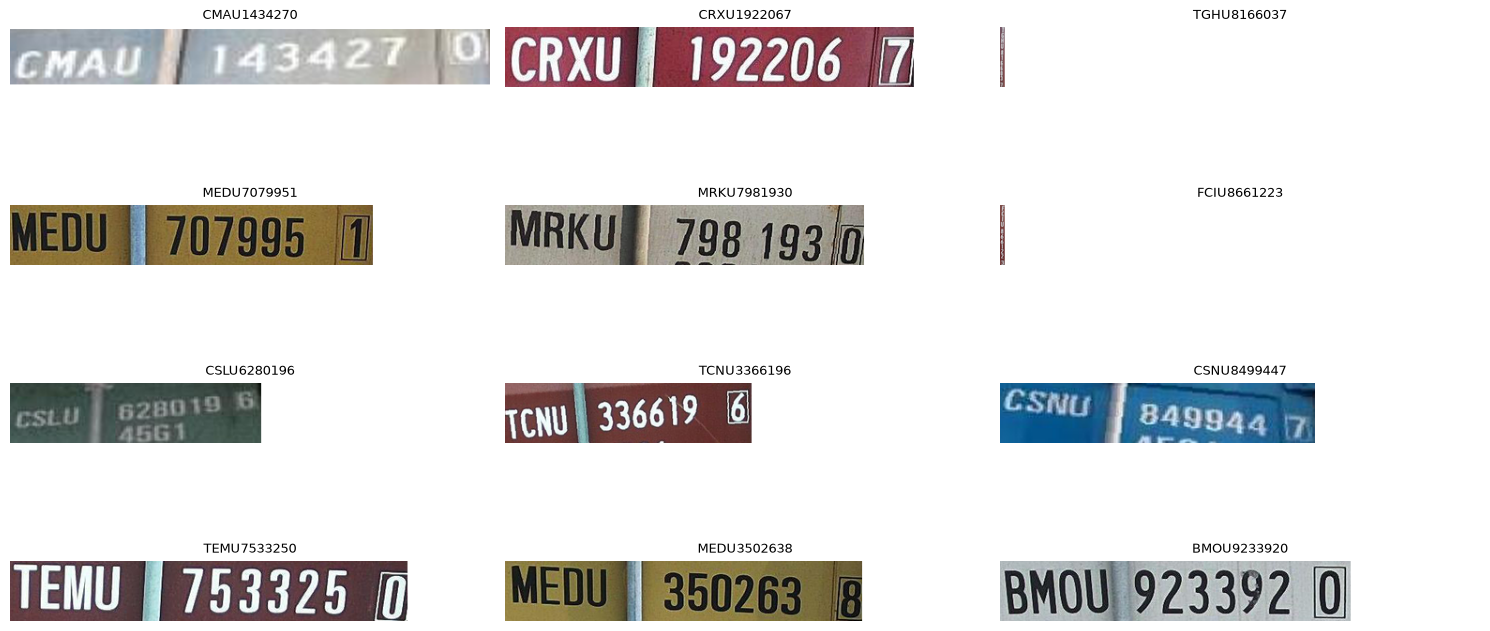

In [58]:
sample_rows = valid_manifest.sample(min(12, len(valid_manifest)), random_state=SEED)

fig, axes = plt.subplots(4, 3, figsize=(15, 8))

for ax, (_, row) in zip(axes.flat, sample_rows.iterrows()):
    crop = resize_and_pad(crop_container_code(row))
    ax.imshow(crop)
    ax.set_title(row["text"], fontsize=9)
    ax.axis("off")

for ax in axes.flat[len(sample_rows):]: ax.axis("off")

plt.tight_layout()
plt.show()

### 3.6. Xử lý và lưu toàn bộ ảnh

Sau khi kiểm tra kết quả cắt và thay đổi kích thước, áp dụng quy trình tiền xử lý cho toàn bộ các bản ghi hợp lệ.

Với mỗi bản ghi:

1. Đọc hình ảnh gốc.
2. Cắt vùng mã container theo bounding box.
3. Thay đổi kích thước và bổ sung vùng đệm về kích thước 64 × 512.
4. Lưu hình ảnh đã xử lý thành tệp PNG.
5. Lưu lại thông tin liên quan đến hình ảnh và nhãn.

Bên cạnh đường dẫn ảnh đã cắt, bảng dữ liệu sau tiền xử lý tiếp tục giữ các thông tin nguồn như `filename`, `image_path`, `xml_path`, `container_id`, `split` và tọa độ bounding box gốc.

Cách tổ chức này giúp liên kết ảnh đã xử lý với annotation ban đầu, thuận tiện cho việc phân tích lỗi và truy xuất dữ liệu sau này.

Những trường hợp gặp lỗi trong quá trình xử lý được lưu riêng để kiểm tra.

In [59]:
processed_rows = []
processing_errors = []

for idx, row in tqdm(valid_manifest.iterrows(), total=len(valid_manifest), desc="Processing crops"):
    try:
        crop = crop_container_code(row)
        processed = resize_and_pad(crop)

        crop_path = CROP_DIR / f"{idx:06d}.png"
        processed.save(crop_path)

        processed_rows.append({
            "filename": row["filename"],
            "image_path": row["image_path"],
            "xml_path": row["xml_path"],
            "crop_path": str(crop_path),
            "text": row["text"],
            "container_id": row["container_id"],
            "split": row["split"],
            "xmin": row["xmin"],
            "ymin": row["ymin"],
            "xmax": row["xmax"],
            "ymax": row["ymax"],
            "bbox_width": row["xmax"] - row["xmin"] + 1,
            "bbox_height": row["ymax"] - row["ymin"] + 1,
            "bbox_ratio": (row["xmax"] - row["xmin"] + 1) / (row["ymax"] - row["ymin"] + 1),
            "encoded": encode_text(row["text"]),
            "label_length": len(row["text"])
        })

    except Exception as e:
        processing_errors.append({
            "filename": row["filename"],
            "image_path": row["image_path"],
            "error": str(e)
        })

processed_df = pd.DataFrame(processed_rows)
processing_errors_df = pd.DataFrame(processing_errors)

print("Valid manifest records:", len(valid_manifest))
print("Successfully processed crops:", len(processed_df))
print("Crop processing errors:", len(processing_errors_df))

Processing crops:   0%|          | 0/4339 [00:00<?, ?it/s]

Valid manifest records: 4339
Successfully processed crops: 4339
Crop processing errors: 0


In [60]:
processed_df.to_csv(OUTPUT_DIR / "processed_manifest.csv", index=False, encoding="utf-8-sig")
processing_errors_df.to_csv(REPORT_DIR / "crop_processing_errors.csv", index=False)

with open(OUTPUT_DIR / "character_vocabulary.json", "w", encoding="utf-8") as f:
    json.dump({
        "char_to_id": char_to_id,
        "id_to_char": {str(k): v for k, v in id_to_char.items()},
        "blank_id": 0,
        "num_classes": NUM_CLASSES
    }, f, ensure_ascii=False, indent=2)

### 3.7. Kiểm tra dữ liệu sau tiền xử lý

Kiểm tra kết quả tiền xử lý bằng cách đối chiếu số lượng bản ghi trong manifest với số lượng ảnh crop thực tế.

Các thông tin được kiểm tra gồm:

- Số bản ghi hợp lệ trong manifest.
- Số bản ghi trong processed manifest.
- Số đường dẫn ảnh crop tồn tại.
- Số tệp PNG thực tế trong thư mục ảnh đã xử lý.
- Số trường hợp lỗi trong quá trình xử lý.

Ngoài ra, kiểm tra kích thước của các ảnh crop đã lưu để xác nhận chúng có cùng kích thước mục tiêu.

Việc đối chiếu này giúp phát hiện các trường hợp ảnh chưa được tạo, tệp bị thiếu hoặc số lượng ảnh trong thư mục không khớp với manifest.

In [61]:
processed_df["crop_exists"] = processed_df["crop_path"].apply(lambda p: Path(p).is_file())

actual_crop_files = [
    p for p in CROP_DIR.iterdir()
    if p.is_file() and p.suffix.lower() == ".png"
]

crop_summary = pd.DataFrame({
    "Metric": [
        "Valid manifest records",
        "Processed manifest records",
        "Existing crop paths in manifest",
        "Actual PNG files in crop directory",
        "Processing errors"
    ],
    "Count": [
        len(valid_manifest),
        len(processed_df),
        int(processed_df["crop_exists"].sum()),
        len(actual_crop_files),
        len(processing_errors_df)
    ]
})

display(crop_summary)
crop_summary.to_csv(REPORT_DIR / "crop_count_summary.csv", index=False)

,Metric,Count
0,Valid manifest records,4339
1,Processed manifest records,4339
2,Existing crop paths in manifest,4339
3,Actual PNG files in crop directory,4339
4,Processing errors,0


In [62]:
crop_dimensions = Counter()

for path in tqdm(processed_df.loc[processed_df["crop_exists"], "crop_path"]):
    with Image.open(path) as img:
        crop_dimensions[img.size] += 1

print("Crop dimensions:", crop_dimensions)

  0%|          | 0/4339 [00:00<?, ?it/s]

Crop dimensions: Counter({(512, 64): 4339})


### 3.8. Chuẩn hóa hình ảnh

Thực hiện chuẩn hóa hình ảnh khi đọc dữ liệu để tạo batch đầu vào cho mô hình.

Ảnh PNG được chuyển thành mảng NumPy với kiểu dữ liệu `float32`, sau đó chia giá trị pixel cho 255 để đưa khoảng giá trị từ [0, 255] về [0, 1].

Việc chuẩn hóa giúp đưa dữ liệu hình ảnh về cùng thang đo và thuận tiện cho quá trình huấn luyện mạng nơ-ron.

Thay vì lưu toàn bộ ảnh dưới dạng mảng float32 trên ổ đĩa, hình ảnh được lưu ở định dạng PNG và chỉ chuyển đổi, chuẩn hóa khi tạo batch. Cách này giúp tiết kiệm dung lượng lưu trữ.

In [63]:
def load_image_batch(paths):
    images = []

    for path in paths:
        with Image.open(path) as img:
            arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
            images.append(arr)

    return np.stack(images).astype(np.float32)

#### Kiểm tra batch đầu vào

In [64]:
sample_paths = processed_df.loc[processed_df["crop_exists"], "crop_path"].head(4).tolist()
sample_batch = load_image_batch(sample_paths)

print("Batch shape:", sample_batch.shape)
print("Data type:", sample_batch.dtype)
print("Pixel range:", sample_batch.min(), "to", sample_batch.max())

Batch shape: (4, 64, 512, 3)
Data type: float32
Pixel range: 0.039215688 to 1.0


### 3.9. Chuẩn bị batch cho CTC

CTC yêu cầu nhãn có độ dài khác nhau được padding về cùng một chiều dài trong batch. ID `0` dành cho *blank*, vì vậy không dùng `0` làm ký tự thực tế.

Trước tiên, xác định chiều dài chuỗi đầu ra của CNN. Ví dụ, nếu CNN giảm chiều rộng tổng cộng 4 lần thì:

$$T = \frac{512}{4} = 128$$

> **Lưu ý:** Đây chỉ là ví dụ; giá trị thực tế phải khớp với kiến trúc CNN của bạn.


In [65]:
TOTAL_WIDTH_STRIDE = 4

assert TARGET_WIDTH % TOTAL_WIDTH_STRIDE == 0

CNN_TIME_STEPS = TARGET_WIDTH // TOTAL_WIDTH_STRIDE

def ctc_required_steps(text):
    repeated_adjacent = sum(text[i] == text[i - 1] for i in range(1, len(text)))
    return len(text) + repeated_adjacent

max_required_steps = processed_df["text"].map(ctc_required_steps).max()

print("CNN time steps:", CNN_TIME_STEPS)
print("Maximum CTC steps required:", max_required_steps)

assert CNN_TIME_STEPS >= max_required_steps, (
    "Chiều dài chuỗi đầu ra CNN không đủ cho CTC. "
    "Cần giảm width stride hoặc tăng kích thước ảnh đầu vào."
)

CNN time steps: 128
Maximum CTC steps required: 16


#### 3.10. Xây dựng batch CTC

In [66]:
def create_ctc_batch(batch_df):
    batch_df = batch_df.reset_index(drop=True)

    images = load_image_batch(batch_df["crop_path"].tolist())

    encoded_labels = [encode_text(text) for text in batch_df["text"]]
    label_lengths = np.array([len(seq) for seq in encoded_labels], dtype=np.int32)

    max_label_len = int(label_lengths.max())
    labels = np.zeros((len(batch_df), max_label_len), dtype=np.int32)

    for i, seq in enumerate(encoded_labels):
        labels[i, :len(seq)] = seq

    input_lengths = np.full(
        (len(batch_df), 1),
        CNN_TIME_STEPS,
        dtype=np.int32
    )

    label_lengths = label_lengths.reshape(-1, 1)

    return {
        "images": images,
        "labels": labels,
        "input_length": input_lengths,
        "label_length": label_lengths
    }

In [67]:
train_df = processed_df[
    (processed_df["split"] == "train") &
    (processed_df["crop_exists"])
].copy()

val_df = processed_df[
    (processed_df["split"] == "val") &
    (processed_df["crop_exists"])
].copy()

test_df = processed_df[
    (processed_df["split"] == "test") &
    (processed_df["crop_exists"])
].copy()

batch = create_ctc_batch(train_df.head(8))

for key, value in batch.items():
    print(key, value.shape, value.dtype)

images (8, 64, 512, 3) float32
labels (8, 11) int32
input_length (8, 1) int32
label_length (8, 1) int32


## 04. Final Data Validation – Kiểm tra tổng thể trước khi xây dựng mô hình

Sau khi hoàn thành tiền xử lý, tổng hợp các chỉ số quan trọng để đánh giá kết quả xử lý toàn bộ bộ dữ liệu.

### 4.1. Tổng hợp kết quả tiền xử lý

Thống kê số lượng XML được xử lý thành công, số bản ghi hợp lệ, số mã container duy nhất, số ảnh crop được tạo và số lượng mẫu trong từng tập huấn luyện, kiểm định và kiểm tra.

Đồng thời, ghi nhận kích thước bộ ký tự và số lớp đầu ra dành cho CTC.

Kết quả được lưu thành tệp `final_data_summary.csv` để phục vụ việc đối chiếu với các lần chạy sau và sử dụng trong báo cáo.

In [68]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total XML files",
        "Successfully parsed XML",
        "Failed XML",
        "Total extracted objects",
        "Valid manifest records",
        "Unique container codes",
        "Successfully processed crops",
        "Existing crop files",
        "Crop processing errors",
        "Train samples",
        "Validation samples",
        "Test samples",
        "Training vocabulary size",
        "Number of CTC classes"
    ],
    "Value": [
        len(xml_status_df),
        int(xml_status_df["parse_success"].sum()),
        int((~xml_status_df["parse_success"]).sum()),
        len(manifest),
        len(valid_manifest),
        valid_manifest["container_id"].nunique(),
        len(processed_df),
        int(processed_df["crop_exists"].sum()),
        len(processing_errors_df),
        len(train_df),
        len(val_df),
        len(test_df),
        len(char_to_id),
        NUM_CLASSES
    ]
})

display(final_summary)
final_summary.to_csv(REPORT_DIR / "final_data_summary.csv", index=False)

,Metric,Value
0,Total XML files,4859
1,Successfully parsed XML,4859
2,Failed XML,0
3,Total extracted objects,4859
4,Valid manifest records,4339
5,Unique container codes,1206
6,Successfully processed crops,4339
7,Existing crop files,4339
8,Crop processing errors,0
9,Train samples,3033


### 4.2. Kiểm tra tính hợp lệ cuối cùng

Thực hiện các điều kiện kiểm tra cuối nhằm xác nhận dữ liệu đã đáp ứng những yêu cầu cơ bản trước khi chuyển sang xây dựng mô hình.

Các điều kiện bao gồm:

- Có ảnh crop được tạo thành công.
- Tất cả đường dẫn ảnh crop trong processed manifest đều tồn tại.
- Nhãn không bị thiếu và có đúng độ dài 11 ký tự.
- Nhãn tuân theo định dạng 4 chữ cái và 7 chữ số.
- Tất cả bản ghi đã được gán tập dữ liệu.
- Không có mã container trùng giữa tập huấn luyện, kiểm định và kiểm tra.
- Chiều dài chuỗi đầu ra CNN đủ đáp ứng yêu cầu của CTC.

Nếu một điều kiện không được đáp ứng, chương trình sẽ dừng để tránh tiếp tục sử dụng dữ liệu chưa đạt yêu cầu.

In [69]:
assert len(processed_df) > 0, "Không có ảnh crop nào được tạo."
assert processed_df["crop_exists"].all(), "Có ảnh crop không tồn tại."
assert processed_df["text"].notna().all(), "Có nhãn bị thiếu."
assert processed_df["text"].str.len().eq(11).all(), "Có nhãn không đủ 11 ký tự."
assert processed_df["text"].str.fullmatch(LABEL_PATTERN).all(), "Có nhãn sai định dạng."
assert processed_df["split"].notna().all(), "Có bản ghi chưa được gán split."

assert set(train_df["container_id"]).isdisjoint(set(val_df["container_id"]))
assert set(train_df["container_id"]).isdisjoint(set(test_df["container_id"]))
assert set(val_df["container_id"]).isdisjoint(set(test_df["container_id"]))

assert all(Path(p).is_file() for p in processed_df["crop_path"])
assert CNN_TIME_STEPS >= max_required_steps

print("All final validation checks passed.")

All final validation checks passed.


### 4.3. Thống kê phân bố các tập dữ liệu

Thống kê số lượng hình ảnh và số mã container duy nhất trong từng tập dữ liệu.

Ngoài ra, tính tỷ lệ số lượng mẫu của mỗi tập so với toàn bộ bộ dữ liệu đã tiền xử lý.

Kết quả giúp xác nhận việc chia dữ liệu có thực hiện đúng theo tỷ lệ dự kiến hay không, đồng thời cung cấp thông tin về số lượng mã container được sử dụng trong từng giai đoạn huấn luyện và đánh giá.

In [70]:
split_distribution = processed_df.groupby("split").agg(
    samples=("filename", "count"),
    unique_containers=("container_id", "nunique"),
    avg_label_length=("label_length", "mean"),
).reindex(["train", "val", "test"])

split_distribution["sample_percentage"] = (
    split_distribution["samples"] / split_distribution["samples"].sum() * 100
)

display(split_distribution)

,samples,unique_containers,avg_label_length,sample_percentage
split,,,,
train,3033,844,11.0,69.900899
val,627,181,11.0,14.450334
test,679,181,11.0,15.648767


## 05. Conclusion

Trong giai đoạn này, ba phần đầu của Task 3 đã được triển khai, bao gồm Khảo sát dữ liệu, Tạo bảng dữ liệu tổng hợp và Tiền xử lý.

Bộ dữ liệu được khảo sát ở các khía cạnh hình ảnh, cấu trúc XML, bounding box và nhãn ký tự. Một manifest được tạo để liên kết từng hình ảnh gốc với nhãn văn bản và tọa độ bounding box tương ứng. Sau đó, các vùng chứa mã được cắt, thay đổi kích thước nhưng vẫn giữ nguyên tỷ lệ và chuẩn bị cho quá trình mã hóa ký tự.

Dữ liệu được chia thành các tập huấn luyện, kiểm định và kiểm tra dựa trên mã container nhằm hạn chế rò rỉ dữ liệu. Bộ ký tự chỉ được xây dựng từ tập huấn luyện. Ngoài ra, hình ảnh sau tiền xử lý và nhãn đã mã hóa được chuẩn bị cho mô hình nhận diện chuỗi sử dụng CTC.

Tuy nhiên, việc tiền xử lý thành công không đồng nghĩa với tất cả annotation đều chính xác. Những bounding box có kích thước bất thường và hình ảnh bị cắt sai vẫn cần được kiểm tra trực quan trước khi huấn luyện mô hình.

Giai đoạn tiếp theo sẽ tập trung xây dựng DataLoader, thiết kế kiến trúc CNN–BiLSTM–CTC, huấn luyện mô hình và đánh giá khả năng nhận diện bằng Character Error Rate (CER) và Exact Match Accuracy.